# Course 2 – Modul 3: Data Split & Polynomial Regression

**Dataset:** Auto MPG (data asli mobil tahun 1970–1982, 398 baris, asal UCI Machine Learning Repository)

**Tujuan:** prediksi konsumsi bensin (`mpg`) dari tenaga mesin (`horsepower`).

**Dua konsep utama:**
- **Data split** → seperti ujian: latihan soal ≠ soal ujian.
- **Polynomial regression** → garis lurus vs garis melengkung.

## 1. Import library
Library standar untuk data, grafik, dan model

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import PolynomialFeatures
from sklearn.pipeline import make_pipeline
from sklearn.metrics import mean_squared_error, r2_score

## 2. Load dataset
Baca file CSV dari folder `data/`.

In [ ]:
df = pd.read_csv("auto_mpg.csv")
df.head()

,mpg,cylinders,displacement,horsepower,weight,acceleration,model_year,origin,name
0,18.0,8,307.0,130.0,3504,12.0,70,usa,chevrolet chevelle malibu
1,15.0,8,350.0,165.0,3693,11.5,70,usa,buick skylark 320
2,18.0,8,318.0,150.0,3436,11.0,70,usa,plymouth satellite
3,16.0,8,304.0,150.0,3433,12.0,70,usa,amc rebel sst
4,17.0,8,302.0,140.0,3449,10.5,70,usa,ford torino


## 3. Cek data
`info()` menunjukkan tipe data dan nilai kosong. Perhatikan `horsepower`.

In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 398 entries, 0 to 397
Data columns (total 9 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   mpg           398 non-null    float64
 1   cylinders     398 non-null    int64  
 2   displacement  398 non-null    float64
 3   horsepower    392 non-null    float64
 4   weight        398 non-null    int64  
 5   acceleration  398 non-null    float64
 6   model_year    398 non-null    int64  
 7   origin        398 non-null    str    
 8   name          398 non-null    str    
dtypes: float64(4), int64(3), str(2)
memory usage: 28.1 KB


## 4. Bersihkan data
Buang baris yang `horsepower`-nya kosong. Ambil hanya kolom yang dipakai.

In [4]:
df = df[["horsepower", "mpg"]].dropna()
print("Jumlah baris:", len(df))
df.describe()

Jumlah baris: 392


,horsepower,mpg
count,392.000000,392.000000
mean,104.469388,23.445918
std,38.491160,7.805007
min,46.000000,9.000000
25%,75.000000,17.000000
50%,93.500000,22.750000
75%,126.000000,29.000000
max,230.000000,46.600000


## 5. Visualisasi
Pola titik melengkung, bukan lurus. Ini alasan kita butuh polinomial.

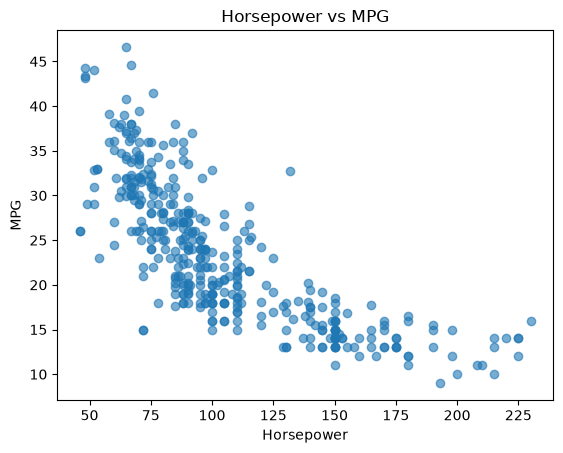

In [5]:
plt.scatter(df["horsepower"], df["mpg"], alpha=0.6)
plt.xlabel("Horsepower")
plt.ylabel("MPG")
plt.title("Horsepower vs MPG")
plt.show()

## 6. Data split
Bagi data jadi **train (80%)** dan **test (20%)**.

- Train = soal latihan.
- Test = soal ujian. Model tidak boleh mengintip.

`random_state=42` supaya hasil selalu sama.

In [6]:
X = df[["horsepower"]]   # fitur (2D)
y = df["mpg"]            # target (1D)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)
print("Train:", X_train.shape, "| Test:", X_test.shape)

Train: (313, 1) | Test: (79, 1)


## 7. Baseline: regresi linear
Model paling sederhana: satu garis lurus. Latih di train, nilai di test.

In [7]:
lin = LinearRegression().fit(X_train, y_train)
pred = lin.predict(X_test)

rmse = np.sqrt(mean_squared_error(y_test, pred))
print(f"Linear  -> R2 test: {r2_score(y_test, pred):.3f} | RMSE test: {rmse:.3f}")

Linear  -> R2 test: 0.566 | RMSE test: 4.707


## 8. Polynomial regression (derajat 2)
`PolynomialFeatures` menambah fitur `x²`. Modelnya tetap linear regression, tapi hasilnya garis melengkung.

`make_pipeline` menggabungkan dua langkah jadi satu model.

In [8]:
poly2 = make_pipeline(PolynomialFeatures(degree=2), LinearRegression())
poly2.fit(X_train, y_train)
pred2 = poly2.predict(X_test)

rmse2 = np.sqrt(mean_squared_error(y_test, pred2))
print(f"Poly-2  -> R2 test: {r2_score(y_test, pred2):.3f} | RMSE test: {rmse2:.3f}")

Poly-2  -> R2 test: 0.639 | RMSE test: 4.291


## 9. Bandingkan visual
Garis merah (linear) vs hijau (derajat 2).

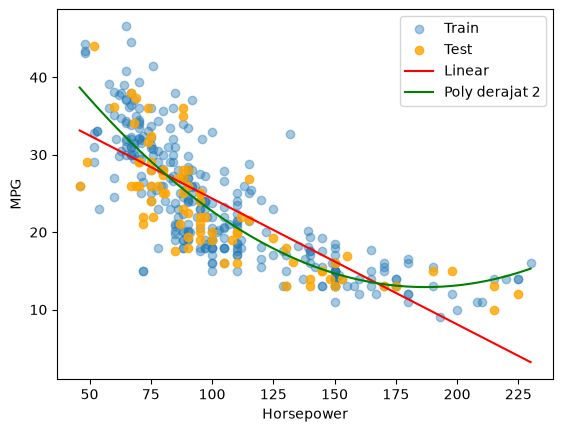

In [9]:
x_line = np.linspace(X["horsepower"].min(), X["horsepower"].max(), 200).reshape(-1, 1)
x_line = pd.DataFrame(x_line, columns=["horsepower"])

plt.scatter(X_train, y_train, alpha=0.4, label="Train")
plt.scatter(X_test, y_test, alpha=0.8, color="orange", label="Test")
plt.plot(x_line, lin.predict(x_line), color="red", label="Linear")
plt.plot(x_line, poly2.predict(x_line), color="green", label="Poly derajat 2")
plt.xlabel("Horsepower")
plt.ylabel("MPG")
plt.legend()
plt.show()

## 10. Cari derajat terbaik
Coba derajat 1 sampai 10. Bandingkan error train dan test.

- **Underfitting:** terlalu sederhana, error tinggi di keduanya.
- **Overfitting:** hafal soal latihan, error test naik lagi.

In [10]:
degrees = range(1, 11)
train_err, test_err = [], []

for d in degrees:
    model = make_pipeline(PolynomialFeatures(d), LinearRegression())
    model.fit(X_train, y_train)
    train_err.append(np.sqrt(mean_squared_error(y_train, model.predict(X_train))))
    test_err.append(np.sqrt(mean_squared_error(y_test, model.predict(X_test))))

result = pd.DataFrame({"degree": degrees, "RMSE_train": train_err, "RMSE_test": test_err})
result.round(3)

,degree,RMSE_train,RMSE_test
0,1,4.947,4.707
1,2,4.382,4.291
2,3,4.523,4.350
3,4,4.837,4.555
4,5,5.215,4.839
5,6,5.580,5.148
6,7,5.905,5.451
7,8,6.192,5.730
8,9,6.445,5.973
9,10,6.666,6.173


## 11. Grafik error vs derajat
Cari derajat di mana error test paling rendah.

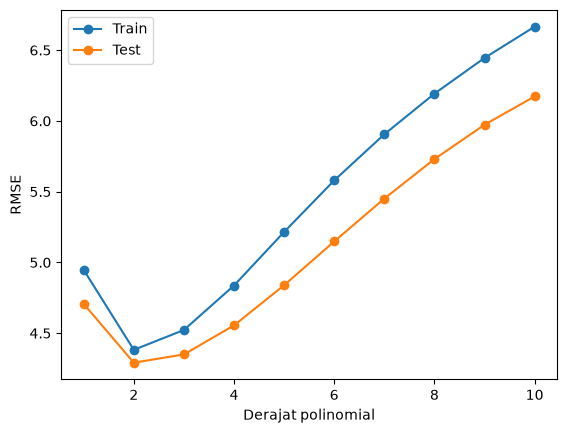

In [11]:
plt.plot(degrees, train_err, marker="o", label="Train")
plt.plot(degrees, test_err, marker="o", label="Test")
plt.xlabel("Derajat polinomial")
plt.ylabel("RMSE")
plt.legend()
plt.show()

## 12. Cross-validation (opsional)
Satu split bisa kebetulan bagus atau jelek. Cross-validation membagi data 5 kali dan merata-ratakan hasilnya, jadi lebih adil.

In [12]:
for d in [1, 2, 3, 5, 8]:
    model = make_pipeline(PolynomialFeatures(d), LinearRegression())
    scores = cross_val_score(model, X, y, cv=5, scoring="neg_root_mean_squared_error")
    print(f"Derajat {d}: RMSE rata-rata = {-scores.mean():.3f}")

Derajat 1: RMSE rata-rata = 5.428
Derajat 2: RMSE rata-rata = 4.747
Derajat 3: RMSE rata-rata = 4.879
Derajat 5: RMSE rata-rata = 5.597
Derajat 8: RMSE rata-rata = 6.642


## Kesimpulan
- Split data dulu, evaluasi **hanya** di test
- Garis lurus = underfitting. Derajat terlalu tinggi = overfitting
- Di data ini, lonjakan terbesar ada di derajat 1 → 2 (RMSE test 4.71 → 4.29). Setelah itu hampir datar
- Derajat 2 sudah cukup. Lebih tinggi = lebih rumit tanpa untung berarti
- Pilih model paling sederhana yang errornya sudah hampir terendah
